# Querying the DFA Superdataset with SQL (semantic-sql)
`superdataset-data.ttl` (the superdataset records, the punned data properties, and the OWL version of the schema) is usually loaded into an rdflib graph and queried with SPARQL. This notebook loads the same file into a SQLite database with [semantic-sql](https://github.com/INCATools/semantic-sql) (`semsql`) and queries it with SQL instead.

**Why try this**
* **Speed**: rdflib parses the 19 MB Turtle file every session (about 10 s) and SPARQL queries over it take from half a second to 15 seconds; the SQLite database is built once (about 5 s with pyoxigraph and rdftab), opens instantly, and the same queries run 35–50 times faster (see the timing cells).
* **Record IDs**: each record has an IRI made from its `Participant_id` (`spreadsheet-to-rdf.py --id-columns Participant_id`), stored in the database as a CURIE, e.g., `superdataset:1234`. The IDs are the same in rdflib, in this database and after rebuilds. (Older versions of the data had blank-node records, whose IDs changed on every load or rebuild.)
* **Same database format as OAK**: the OHD database used for term enrichment is also a semsql database, so data and ontology can be combined with plain SQL.

**How the data looks in semsql**
* Every triple is a row in the `statements` table: `subject`, `predicate`, `object` (IRIs/CURIEs) or `value` (literals) and `datatype`.
* A record is a set of rows with the same `subject`; e.g., `superdataset:1234 | superdataset:dfs1 | 3`.
* Class relationships (including the punned items, e.g., `superdataset:dfs1 rdfs:subClassOf OHD:0000421`) are in the `edge` view; `entailed_edge` (inferred ancestors) is only filled by the full `semsql make` build.

**Things to know**
* **Values are stored as text**, even integers. Use `CAST(value AS INTEGER)` for numeric comparisons; otherwise SQL compares strings (e.g., `'-9999' >= 4` gives the wrong answer).
* **Prefixes**: the database shortens IRIs to CURIEs using semsql's standard prefix list plus `superdataset:`. Without the standard list, predicates such as `rdfs:subClassOf` are stored as full IRIs.

**Requirements**
* `DFA-data/superdataset-data.ttl`: run `make superdataset-data.ttl` from the root directory to build.
* To build the database: [rdftab](https://github.com/ontodev/rdftab.rs) on the `PATH`, and the `pyoxigraph` and `semsql` python packages (semsql provides the schema and prefixes). [ROBOT](https://robot.obolibrary.org/) is also needed for OWL-only inputs (Functional/Manchester Syntax, OWL/XML, OBO) and for the full `semsql` build, which also needs `relation-graph`.
* python packages: `pandas`, `pyoxigraph`, `semsql`, `oaklib`, `linkml` (and `rdflib` for the optional SPARQL comparison).
* For the enrichment section: `DFA-data/enrichment/ohd.db`, built by step 1 of `superdataset-term-enrichment.ipynb`.

In [1]:
import shutil
import sqlite3
from pathlib import Path

import pandas as pd
from IPython.display import display
from linkml_runtime import SchemaView
from oaklib import get_adapter
from oaklib.datamodels.vocabulary import IS_A
from rdflib import Graph

from lib.superdataset_analysis_utils import (
    build_semsql_db,
    sql_df,
    sparql_df,
    timed,
    run_enrichment,
    plot_enrichment,
)

/opt/homebrew/lib/python3.11/site-packages/eutils/__init__.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


## helper functions
The helper functions are in [`lib/superdataset_analysis_utils.py`](lib/superdataset_analysis_utils.py) and are imported at the top of the notebook. This notebook uses:
* `build_semsql_db(data_path, db_path, ...)`: build a semantic-sql (SQLite) database from an RDF/OWL file (serialization detected with `detect_rdf_format`)
* `sql_df(query, con)`: run a SQL query on a SQLite connection and return a DataFrame
* `sparql_df(query, source)`: run a SPARQL SELECT query on an rdflib `Graph` or a SPARQL endpoint URL and return a DataFrame
* `timed(label, func, *args, **kwargs)`: call a function and print how long it took
* `run_enrichment(adapter, sample, background, direction="greater", ...)`: OAK-style class enrichment (over-, under-represented or two-sided) as a DataFrame (used in section 6)
* `plot_enrichment(adapter, enrichment, imgfile, ...)`: draw enrichment results with OAK's graph visualization (used in section 6)

Use `help(<function>)` for the details of a function.

## settings
All generated files go in `DFA-data/semsql/` (gitignored, because the database contains participant data). The enrichment section uses a copy of the OHD database, so the files of `superdataset-term-enrichment.ipynb` are not changed.

In [2]:
DATA_TTL = Path("DFA-data/superdataset-data.ttl")       # superdataset records + schema + puns
                                                        # (any RDF/OWL serialization works, e.g. an RDF/XML .owl)
SEMSQL_DIR = Path("DFA-data/semsql")                    # gitignored (contains participant data)
DATA_DB = SEMSQL_DIR / "superdataset-data.db"           # superdataset as semantic-sql database
OHD_DB = Path("DFA-data/enrichment/ohd.db")             # OHD database (from the enrichment notebook)
OHD_DFA_SQL_DB = SEMSQL_DIR / "ohd-dfa-sql.db"          # OHD + associations built with SQL
OHD_DFA_SUBSCALE_DB = SEMSQL_DIR / "ohd-dfa-subscales.db" # OHD + DFS subscale associations (section 6)
OHD_DFA_SUBSCALE_PLOT_DB = SEMSQL_DIR / "ohd-dfa-subscales-plot.db"  # copy used only to draw section 6
SCHEMA = "../src/schema/superdataset.yaml"
PREFIXES = {"superdataset": "https://w3id.org/OHD/DFA-study/superdataset/"}

SEMSQL_DIR.mkdir(parents=True, exist_ok=True)

## 1. Build the database
`build_semsql_db` detects the input file's serialization from its content, not its extension (`detect_rdf_format`), because extensions are not reliable (e.g., OWL Functional Syntax is sometimes saved as `.owl`). rdftab and semsql read RDF/XML, so:
* **RDF/XML** is loaded as is, with no conversion;
* **Turtle, N-Triples and JSON-LD** are converted with pyoxigraph (under a second for this file);
* **OWL Functional Syntax, Manchester Syntax, OWL/XML and OBO** are converted with ROBOT.

The input file is never changed. Use `input_format=` to skip detection.

By default the database is built with **rdftab** (about 5 seconds): [pyoxigraph](https://pyoxigraph.readthedocs.io/) converts the Turtle file to RDF/XML in under a second (ROBOT takes about 3.5 s and rdflib about 11 s; all three give the same database), rdftab loads the triples into the `statements` table, and the semsql schema provides the views (e.g., `edge`, `rdfs_label_statement`). The full `semsql make` build (`method="semsql"`, about 11 seconds) also runs relation-graph to fill `entailed_edge` with all inferred ancestors; this notebook does not need it, because the enrichment uses the OHD database's own `entailed_edge`. Both methods give the same `statements` table.

The database is only built if it doesn't exist; set `REBUILD = True` after `superdataset-data.ttl` changes (or to switch methods).

In [3]:
REBUILD = False
METHOD = "rdftab"      # or "semsql" for the full build (adds entailed_edge)

timed("build", build_semsql_db, DATA_TTL, DATA_DB, extra_prefixes=PREFIXES, method=METHOD, rebuild=REBUILD)
con = sqlite3.connect(DATA_DB)
print(f"{DATA_DB}: {DATA_DB.stat().st_size / 1e6:.0f} MB")

build: 0.000 s
DFA-data/semsql/superdataset-data.db: 139 MB


## 2. Explore the database
The main table is `statements` (every triple). semsql's schema also defines views over it, e.g., `edge` (asserted class relationships, such as the punned items) and `rdfs_label_statement`. `entailed_edge` (inferred relationships) is only filled by the full `semsql` build.

In [4]:
sql_df("""
SELECT 'statements' AS "table", COUNT(*) AS "rows" FROM statements
UNION ALL SELECT 'edge', COUNT(*) FROM edge
UNION ALL SELECT 'entailed_edge (empty unless method="semsql")', COUNT(*) FROM entailed_edge
UNION ALL SELECT 'records (subjects with a superdataset:source)',
                 COUNT(DISTINCT subject) FROM statements WHERE predicate = 'superdataset:source'
""", con)

,table,rows
0,statements,651451
1,edge,48
2,"entailed_edge (empty unless method=""semsql"")",0
3,records (subjects with a superdataset:source),10163


One record, as rows of `statements` (participant IDs left out). Note that `value` holds the answer as text and `datatype` says it is an integer:

In [5]:
sql_df("""
SELECT subject, predicate, value, datatype
FROM statements
WHERE subject = (SELECT subject FROM statements WHERE predicate = 'superdataset:source' LIMIT 1)
  AND predicate NOT LIKE 'superdataset:Participant%'
LIMIT 12
""", con)

,subject,predicate,value,datatype
0,superdataset:1,superdataset:Age,44,xsd:integer
1,superdataset:1,superdataset:Ethnicity_new,1,xsd:integer
2,superdataset:1,superdataset:Last_Dental_Visit,1,xsd:integer
3,superdataset:1,superdataset:Race,1,xsd:integer
4,superdataset:1,superdataset:Sex,2,xsd:integer
5,superdataset:1,superdataset:agegrp,3,xsd:integer
6,superdataset:1,superdataset:dfs1,3,xsd:integer
7,superdataset:1,superdataset:dfs10,2,xsd:integer
8,superdataset:1,superdataset:dfs11,2,xsd:integer
9,superdataset:1,superdataset:dfs12,2,xsd:integer


The punned data properties link each question slot to its OHD class, in `edge`:

In [6]:
sql_df("""
SELECT e.subject AS slot, e.object AS ohd_class, l.value AS slot_label
FROM edge e LEFT JOIN rdfs_label_statement l ON l.subject = e.subject
WHERE e.subject LIKE 'superdataset:%' AND e.predicate = 'rdfs:subClassOf' AND e.object LIKE 'OHD:%'
ORDER BY e.subject
LIMIT 10
""", con)

,slot,ohd_class,slot_label
0,superdataset:dfs1,OHD:0000421,dfs1
1,superdataset:dfs10,OHD:0000431,dfs10
2,superdataset:dfs11,OHD:0000432,dfs11
3,superdataset:dfs12,OHD:0000433,dfs12
4,superdataset:dfs13,OHD:0000434,dfs13
5,superdataset:dfs14,OHD:0000435,dfs14
6,superdataset:dfs15,OHD:0000436,dfs15
7,superdataset:dfs16,OHD:0000437,dfs16
8,superdataset:dfs17,OHD:0000438,dfs17
9,superdataset:dfs18,OHD:0000439,dfs18


## 3. Queries: SQL and SPARQL side by side
The SQL query below gives the same result as the SPARQL query in `superdataset-to-rdf.ipynb`: the mean DFS total score by study, without the missing (`-9999`) and not asked (`-9876`) codes. Each property of a record is a separate row, so the query joins `statements` to itself on `subject`.

In [7]:
q_mean_sql = """
SELECT s.value AS source,
       SUM(CAST(t.value AS INTEGER) >= 0)      AS n_valid,
       SUM(CAST(t.value AS INTEGER) = -9999)   AS n_missing,
       SUM(CAST(t.value AS INTEGER) = -9876)   AS n_not_asked,
       AVG(CASE WHEN CAST(t.value AS INTEGER) >= 0 THEN CAST(t.value AS INTEGER) END) AS mean_dfs_total
FROM statements s
JOIN statements t ON t.subject = s.subject AND t.predicate = 'superdataset:dfs_total_score'
WHERE s.predicate = 'superdataset:source'
GROUP BY s.value
ORDER BY s.value
"""
mean_sql = timed("SQL", sql_df, q_mean_sql, con)
mean_sql.round(1)

SQL: 0.016 s


,source,n_valid,n_missing,n_not_asked,mean_dfs_total
0,bph,164,3,0,39.8
1,bwhs,0,0,484,NaN
2,cohra1,1488,156,0,37.0
3,cohra2,1478,6,0,33.5
4,f31,102,0,0,46.0
5,mdas,0,0,72,NaN
6,randall,552,122,0,43.4
7,sohea,0,0,5067,NaN
8,tic,466,3,0,43.2


#### Optional: compare with SPARQL
Loads `superdataset-data.ttl` into rdflib (about 10 seconds) and runs the SPARQL version of the same query.

In [8]:
g = timed("rdflib: load superdataset-data.ttl", Graph().parse, DATA_TTL)

q_mean_sparql = """
PREFIX sd: <https://w3id.org/OHD/DFA-study/superdataset/>
SELECT ?source
       (SUM(IF(?score >= 0, 1, 0)) AS ?n_valid)
       (SUM(IF(?score = -9999, 1, 0)) AS ?n_missing)
       (SUM(IF(?score = -9876, 1, 0)) AS ?n_not_asked)
       (AVG(IF(?score >= 0, ?score, ?unbound)) AS ?mean_dfs_total)
WHERE { ?r sd:source ?source ; sd:dfs_total_score ?score }
GROUP BY ?source
ORDER BY ?source
"""
mean_sparql = timed("SPARQL", sparql_df, q_mean_sparql, g)

cols = ["source", "n_valid", "n_missing", "n_not_asked"]
print("same counts:", mean_sql[cols].astype(str).equals(mean_sparql[cols].astype(str)),
      "| same means:", ((mean_sql.mean_dfs_total - mean_sparql.mean_dfs_total.astype(float)).abs().fillna(0) < 1e-9).all())

rdflib: load superdataset-data.ttl: 9.624 s
SPARQL: 0.832 s
same counts: True | same means: True


## 4. The whole dataset as a DataFrame
Pivoting the record rows gives one row per record and one column per property, i.e., the original spreadsheet with the record IDs added. This is a quick way to use the RDF data with pandas.

In [9]:
q_records = """
SELECT subject AS record, predicate, value
FROM statements
WHERE subject IN (SELECT subject FROM statements WHERE predicate = 'superdataset:source')
  AND predicate LIKE 'superdataset:%'
"""
long = timed("SQL", sql_df, q_records, con)
records = long.pivot(index="record", columns="predicate", values="value")
records.columns = [c.replace("superdataset:", "") for c in records.columns]

# values are text in the database: convert the columns that hold numbers (IDs stay text)
def to_number(col):
    if col.name in ("source", "Participant_id", "Participant_id_original"):
        return col
    try:
        return pd.to_numeric(col)
    except (ValueError, TypeError):
        return col
records = records.apply(to_number)
print(records.shape)
records[["source", "Age", "Sex", "Last_Dental_Visit", "dfs1", "dfs_total_score"]].head()

SQL: 0.282 s
(10163, 64)


,source,Age,Sex,Last_Dental_Visit,dfs1,dfs_total_score
record,,,,,,
superdataset:1,bph,44,2,1,3,69
superdataset:10,bph,56,2,1,1,23
superdataset:100,bph,57,1,3,3,55
superdataset:1000,cohra1,14,1,1,1,29
superdataset:10000,tic,31,2,1,1,20


## 5. Term enrichment with SQL-built associations
The term enrichment notebook builds its associations (record → OHD question class, for positive answers) with SPARQL. The same associations can be built with one SQL query here, and inserted into a copy of the OHD database by attaching the superdataset database. Because the records have fixed IDs (`superdataset:<Participant_id>`), the associations stay valid across sessions and rebuilds.

A **positive** answer is defined as in the enrichment notebook: 4 or 5 on the 1–5 scales, and 1 (*Yes*) for yes/no items.

In [10]:
# minimum value that counts as a positive answer, for each punned question slot
sv = SchemaView(SCHEMA)
positive_min = pd.DataFrame(
    [
        (f"superdataset:{name}", 1 if sv.induced_slot(name, "Record").range == "NoYesMissing" else 4)
         for name in sv.class_slots("Record")
         if "pun_as" in (sv.induced_slot(name, "Record").annotations or {})
    ],
    columns=["item", "min_positive"]
)
positive_min.to_sql("positive_min", con, if_exists="replace", index=False)

q_assoc = """
SELECT st.subject AS record, e.object AS ohd_class
FROM positive_min p
JOIN edge e ON e.subject = p.item AND e.predicate = 'rdfs:subClassOf' AND e.object LIKE 'OHD:%'
JOIN statements st ON st.predicate = p.item AND CAST(st.value AS INTEGER) >= p.min_positive
"""
assoc = timed("SQL", sql_df, q_assoc, con)
print(f"{len(positive_min)} questions, {len(assoc):,} associations, {assoc.record.nunique():,} records")

SQL: 0.424 s
48 questions, 22,877 associations, 4,468 records


#### Optional: the same associations with SPARQL
Needs `g` from the comparison cell in section 3.

In [11]:
values = " ".join(f"(sd:{item.split(':')[1]} {n})" for item, n in positive_min.itertuples(index=False))
q_assoc_sparql = f"""
PREFIX sd: <https://w3id.org/OHD/DFA-study/superdataset/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
SELECT ?record ?ohd_class
WHERE {{
  VALUES (?item ?min_positive) {{ {values} }}
  ?item rdfs:subClassOf ?ohd_class .
  FILTER(STRSTARTS(STR(?ohd_class), "http://purl.obolibrary.org/obo/OHD_"))
  ?record ?item ?value .
  FILTER(?value >= ?min_positive)
}}
"""
assoc_sparql = timed("SPARQL", sparql_df, q_assoc_sparql, g)
assoc_sparql["ohd_class"] = assoc_sparql.ohd_class.str.replace("http://purl.obolibrary.org/obo/OHD_", "OHD:")
per_class = lambda df: df.groupby("ohd_class").record.nunique().sort_index().astype(int)
print(f"rows: SQL {len(assoc):,} | SPARQL {len(assoc_sparql):,} | same records per class: {per_class(assoc).equals(per_class(assoc_sparql))}")

SPARQL: 15.229 s
rows: SQL 22,877 | SPARQL 22,877 | same records per class: True


Insert the associations into a copy of the **OHD database**. `ATTACH` lets one SQL statement read from the superdataset database and write to the OHD database. The record CURIEs (`superdataset:<Participant_id>`) are used directly as the OAK subjects.

In [12]:
shutil.copy(OHD_DB, OHD_DFA_SQL_DB)
with sqlite3.connect(OHD_DFA_SQL_DB) as ohd_con:
    ohd_con.execute("ATTACH DATABASE ? AS data", (str(DATA_DB),))
    ohd_con.execute("DELETE FROM term_association")
    ohd_con.execute("""
        INSERT INTO term_association (id, subject, predicate, object, source)
        SELECT DISTINCT 
               st.subject || '|' || e.object,
               st.subject, 
               'OHD:has_positive_response', 
               e.object,
               'infores:dfa-superdataset'
        FROM data.positive_min p
        JOIN data.edge e 
            ON e.subject = p.item 
            AND e.predicate = 'rdfs:subClassOf' AND e.object LIKE 'OHD:%'
        JOIN data.statements st 
            ON st.predicate = p.item 
            AND CAST(st.value AS INTEGER) >= p.min_positive
    """)
    ohd_con.execute("CREATE INDEX IF NOT EXISTS ta_subject ON term_association(subject)")
    ohd_con.execute("CREATE INDEX IF NOT EXISTS ta_object ON term_association(object)")
    ohd_con.commit()
    print("term_association rows:", ohd_con.execute("SELECT COUNT(*) FROM term_association").fetchone()[0])

adapter = get_adapter(f"sqlite:{OHD_DFA_SQL_DB}")
adapter.can_store_associations = True   # use the SQL association queries (see the enrichment notebook)

term_association rows: 22877


In [13]:
sql_df("select * from term_association limit 5", ohd_con)

,id,subject,predicate,object,evidence_type,publication,source
0,superdataset:10011|OHD:0000421,superdataset:10011,OHD:has_positive_response,OHD:0000421,None,None,infores:dfa-superdataset
1,superdataset:10012|OHD:0000421,superdataset:10012,OHD:has_positive_response,OHD:0000421,None,None,infores:dfa-superdataset
2,superdataset:10013|OHD:0000421,superdataset:10013,OHD:has_positive_response,OHD:0000421,None,None,infores:dfa-superdataset
3,superdataset:10015|OHD:0000421,superdataset:10015,OHD:has_positive_response,OHD:0000421,None,None,infores:dfa-superdataset
4,superdataset:1004|OHD:0000421,superdataset:1004,OHD:has_positive_response,OHD:0000421,None,None,infores:dfa-superdataset


Define the sample and background with SQL, as in the enrichment notebook's main example:
* **background**: records with a DFS answer and a known `Last_Dental_Visit`
* **sample**: background records whose last visit was 5 or more years ago or never

In [14]:
q_people = """
SELECT 
    v.subject AS subject, 
    CAST(v.value AS INTEGER) AS last_visit
FROM statements v
JOIN statements d 
    ON d.subject = v.subject AND d.predicate = 'superdataset:dfs1'
WHERE v.predicate = 'superdataset:Last_Dental_Visit'
  AND CAST(d.value AS INTEGER) >= 1          -- answered the DFS
  AND CAST(v.value AS INTEGER) >= 1          -- last visit known
"""
people = sql_df(q_people, con)
background = people["subject"].tolist()
sample = people.loc[people.last_visit.isin([4, 5]), "subject"].tolist()
print(f"background: {len(background):,} records | sample: {len(sample):,} records")

background: 4,290 records | sample: 498 records


In [15]:
people.head()

,subject,last_visit
0,superdataset:1,1
1,superdataset:10,1
2,superdataset:100,3
3,superdataset:1000,1
4,superdataset:10000,1


Run OAK's enrichment (over-representation). The results should match the main example in `superdataset-term-enrichment.ipynb` (e.g., DFS 01: 22.1% of the sample vs 13.2% of the background).

In [16]:
results = timed(
    "enrichment", 
    lambda: list(adapter.enriched_classes(
                            subjects=sample, 
                            background=background, 
                            object_closure_predicates=[IS_A],
                            cutoff=0.05, 
                            autolabel=True)))
enrichment = pd.DataFrame([{
    "class_id": r.class_id, 
    "class_label": r.class_label,
    "sample_pct": round(100 * r.sample_count / r.sample_total, 1),
    "background_pct": round(100 * r.background_count / r.background_total, 1),
    "p_value_adjusted": r.p_value_adjusted} for r in results])

enrichment

enrichment: 0.431 s


,class_id,class_label,sample_pct,background_pct,p_value_adjusted
0,OHD:0000421,DFS 01. Has fear of dental work ever caused yo...,22.1,13.2,2.180198e-07
1,OHD:0008024,question about delay in scheduling a dental ap...,24.9,16.0,2.462598e-06
2,OHD:0008022,dental visit avoidance question,27.3,18.3,5.663198e-06
3,OHD:0008021,health encounter avoidance question,27.3,18.3,5.663198e-06
4,OHD:0008020,avoidance behavior question,27.3,18.3,5.663198e-06
5,OHD:0000422,DFS 02. Has fear of dental work ever caused yo...,11.0,6.2,6.011466e-04
6,OHD:0008023,question about canceling or not showing up for...,11.0,6.2,6.011466e-04
7,OHD:0000429,DFS 08. Making an appointment for dentistry.,9.8,5.5,1.213654e-03
8,OHD:0000430,DFS 09. Approaching the dentist’s office.,11.0,6.9,1.133912e-02
9,OHD:0000441,"DFS 20. All things considered, how fearful are...",20.9,15.3,1.604363e-02


## 6. Enrichment test: DFS subscale scores by sex
*Are high DFS subscale or total scores more or less common among men, or among women, than in the whole DFS population?*

The DFS has three subscales and a total score, stored as sums of item answers:

| score | items | score range | closest OHD class |
|---|---|---|---|
| `dfs_avoidance_fear` | 1, 2, 8–13 | 8–40 | OHD:0008007 *avoidance or anticipatory fear question* (but OHD also puts items 14–19 under it) |
| `dfs_specific_stimuli_fear` | 14–19 | 6–30 | OHD:0008046 *fear of specific dental stimuli question* (same items) |
| `dfs_physiological_arousal` | 3–7 | 5–25 | OHD:0008047 *question about physiological arousal* (same items) |
| `dfs_total_score` | 1–20 | 20–100 | OHD:0008010 *Dental Fear Survey (DFS) question* |

**Why the scores get their own classes:** enrichment counts a record under every ancestor of its classes. In OHD, *fear of specific dental stimuli question* is a subclass of *avoidance or anticipatory fear question*, and all three are under *DFS question*. Linking records to those OHD classes would count everyone with a high specific-stimuli score as high on avoidance, and everyone with any high subscale as high on the total. Instead, each score gets its own class (e.g., `superdataset:dfs_avoidance_fear`) with no hierarchy, so each is tested separately; the table above shows how they correspond to OHD.

**High score**: an average item score of `HIGH_MEAN_ITEM` (default 4, *often / much* or more) or higher, the same level as a *positive* answer in the item-level enrichment. For example, a high avoidance score is 4 × 8 = 32 or more.

* **background**: all DFS respondents with a valid total score
* **samples**: men (`Sex` = 1) and women (`Sex` = 2), each compared with the whole background; the test is two-sided because there is no expected direction

The associations go into their own copy of the OHD database (`OHD_DFA_SUBSCALE_DB`), so they are not mixed with the item-level associations of section 5.

In [17]:
HIGH_MEAN_ITEM = 4      # average item score that counts as high (4 = often / much)

SUBSCALES = pd.DataFrame([
    ("superdataset:dfs_avoidance_fear",        "DFS avoidance subscale (items 1, 2, 8-13)",      8, "OHD:0008007"),
    ("superdataset:dfs_specific_stimuli_fear", "DFS specific stimuli subscale (items 14-19)",    6, "OHD:0008046"),
    ("superdataset:dfs_physiological_arousal", "DFS physiological arousal subscale (items 3-7)", 5, "OHD:0008047"),
    ("superdataset:dfs_total_score",           "DFS total score (items 1-20)",                   20, "OHD:0008010"),
], columns=["score", "label", "n_items", "ohd_class"])
SUBSCALES["min_high"] = HIGH_MEAN_ITEM * SUBSCALES["n_items"]
SUBSCALES[["score", "min_high"]].to_sql("subscale_high", con, if_exists="replace", index=False)

# associations: record -> score class, when the score is high
high = sql_df("""
SELECT st.subject AS subject, st.predicate AS object
FROM subscale_high h
JOIN statements st ON st.predicate = h.score AND CAST(st.value AS INTEGER) >= h.min_high
""", con)

# copy of OHD with the associations; each score class only has itself as "ancestor"
shutil.copy(OHD_DB, OHD_DFA_SUBSCALE_DB)
with sqlite3.connect(OHD_DFA_SUBSCALE_DB) as sub_con:
    sub_con.execute("DELETE FROM term_association")
    high.assign(id=high.subject + "|" + high.object, predicate="OHD:has_high_score",
                source="infores:dfa-superdataset")[["id", "subject", "predicate", "object", "source"]].to_sql(
        "term_association", sub_con, if_exists="append", index=False)
    for s in SUBSCALES.itertuples():
        sub_con.execute("INSERT INTO entailed_edge (subject, predicate, object) VALUES (?, 'rdfs:subClassOf', ?)",
                        (s.score, s.score))
        sub_con.execute("INSERT INTO statements (subject, predicate, value) VALUES (?, 'rdfs:label', ?)",
                        (s.score, s.label))
    sub_con.commit()
sub_adapter = get_adapter(f"sqlite:{OHD_DFA_SUBSCALE_DB}")
sub_adapter.can_store_associations = True

SUBSCALES.merge(high.object.value_counts().rename("n_high"), left_on="score", right_index=True)

,score,label,n_items,ohd_class,min_high,n_high
0,superdataset:dfs_avoidance_fear,"DFS avoidance subscale (items 1, 2, 8-13)",8,OHD:0008007,32,162
1,superdataset:dfs_specific_stimuli_fear,DFS specific stimuli subscale (items 14-19),6,OHD:0008046,24,730
2,superdataset:dfs_physiological_arousal,DFS physiological arousal subscale (items 3-7),5,OHD:0008047,20,215
3,superdataset:dfs_total_score,DFS total score (items 1-20),20,OHD:0008010,80,182


In [18]:
q_dfs_people = """
SELECT t.subject AS subject, CAST(s.value AS INTEGER) AS sex, src.value AS source
FROM statements t
JOIN statements s   ON s.subject = t.subject   AND s.predicate = 'superdataset:Sex'
JOIN statements src ON src.subject = t.subject AND src.predicate = 'superdataset:source'
WHERE t.predicate = 'superdataset:dfs_total_score' AND CAST(t.value AS INTEGER) >= 0
"""
dfs_people = sql_df(q_dfs_people, con)
background_dfs = dfs_people["subject"].tolist()
print(f"background: {len(background_dfs):,} DFS respondents | by sex: {dfs_people.sex.value_counts().to_dict()}")

by_sex = []
for name, code in (("men", 1), ("women", 2)):
    sample_sex = dfs_people.loc[dfs_people.sex == code, "subject"].tolist()
    r = run_enrichment(sub_adapter, sample_sex, background_dfs, direction="two-sided", cutoff=1.0)
    by_sex.append(r.assign(sample=f"{name} (n={len(sample_sex):,})"))
by_sex = pd.concat(by_sex, ignore_index=True)
by_sex[["sample", "class_label", "direction", "sample_count", "sample_pct", "background_pct",
        "p_value", "p_value_adjusted"]]

background: 4,250 DFS respondents | by sex: {2: 3154, 1: 1081, 3: 11, -9999: 4}


,sample,class_label,direction,sample_count,sample_pct,background_pct,p_value,p_value_adjusted
0,"men (n=1,081)",DFS specific stimuli subscale (items 14-19),under,139,12.9,16.5,0.000173,0.000693
1,"men (n=1,081)",DFS physiological arousal subscale (items 3-7),under,34,3.1,4.7,0.004564,0.018258
2,"men (n=1,081)",DFS total score (items 1-20),under,33,3.1,4.3,0.023332,0.093328
3,"men (n=1,081)","DFS avoidance subscale (items 1, 2, 8-13)",under,31,2.9,3.6,0.155799,0.623196
4,"women (n=3,154)",DFS specific stimuli subscale (items 14-19),over,560,17.8,16.5,0.000153,0.000614
5,"women (n=3,154)",DFS physiological arousal subscale (items 3-7),over,165,5.2,4.7,0.006111,0.024446
6,"women (n=3,154)",DFS total score (items 1-20),over,148,4.7,4.3,0.024331,0.097324
7,"women (n=3,154)","DFS avoidance subscale (items 1, 2, 8-13)",over,121,3.8,3.6,0.187295,0.749180


#### Figures
`plot_enrichment` draws the results like the term enrichment figures: orange ▲ = more common in the sample than in the whole population, blue ▼ = less common, with thicker, darker borders for smaller adjusted p-values. Scores that are not significant are white and marked *(n.s.)*.

The four score classes have no hierarchy (so each is tested separately), but `plot_enrichment` draws a class hierarchy. The figures therefore use a copy of the database (`OHD_DFA_SUBSCALE_PLOT_DB`) with one extra class, *DFS score*, above the four scores; it is only used for drawing, so it does not change the results above. The images are also saved to `SEMSQL_DIR`.

men (n=1,081)


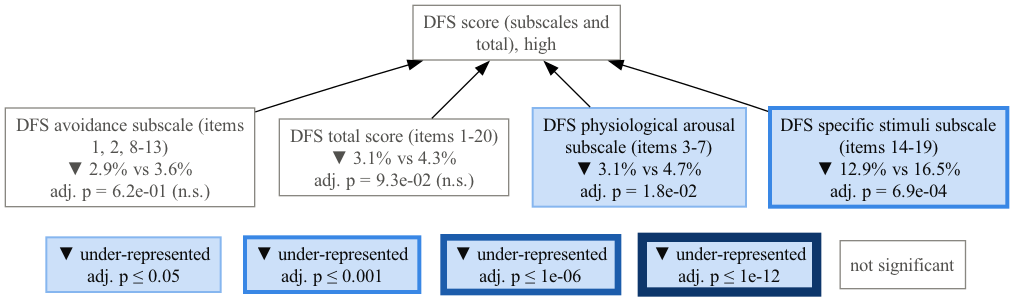

women (n=3,154)


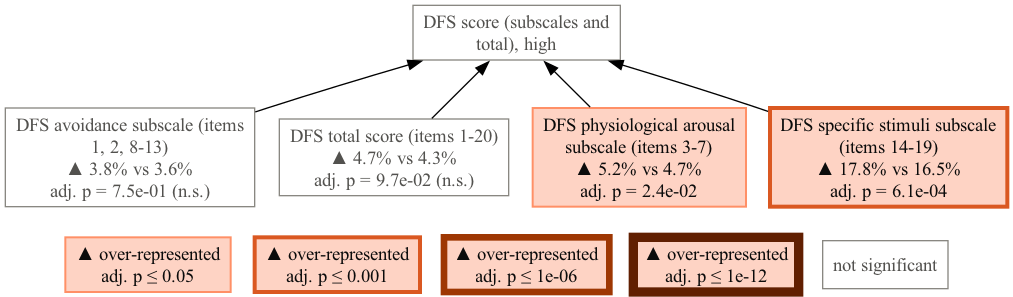

In [19]:
# drawing copy: one grouping class above the four score classes
SCORE_GROUP = "superdataset:dfs_score"
shutil.copy(OHD_DFA_SUBSCALE_DB, OHD_DFA_SUBSCALE_PLOT_DB)
with sqlite3.connect(OHD_DFA_SUBSCALE_PLOT_DB) as plot_con:
    plot_con.execute("INSERT INTO statements (subject, predicate, value) VALUES (?, 'rdfs:label', ?)",
                     (SCORE_GROUP, "DFS score (subscales and total), high"))
    plot_con.execute("INSERT INTO entailed_edge (subject, predicate, object) VALUES (?, 'rdfs:subClassOf', ?)",
                     (SCORE_GROUP, SCORE_GROUP))
    for score in SUBSCALES["score"]:
        plot_con.execute("INSERT INTO statements (subject, predicate, object) VALUES (?, 'rdfs:subClassOf', ?)",
                         (score, SCORE_GROUP))
        plot_con.execute("INSERT INTO entailed_edge (subject, predicate, object) VALUES (?, 'rdfs:subClassOf', ?)",
                         (score, SCORE_GROUP))
    plot_con.commit()
plot_adapter = get_adapter(f"sqlite:{OHD_DFA_SUBSCALE_PLOT_DB}")

for sample_name, results in by_sex.groupby("sample", sort=False):
    print(sample_name)
    name = sample_name.split()[0]          # "men" / "women"
    plot_enrichment(
        plot_adapter, 
        results,
        SEMSQL_DIR / f"dfs-scores-high_{name}-vs-all.png", 
        top_class=SCORE_GROUP,
        legend_orientation='horizontal'
    )

**Check: is the sex difference the same within studies?** Studies differ in how many women they enrolled (cohra2 enrolled only women) and in how much fear their participants report. The table shows the percentage with a high score by study and sex, and the odds ratio for women vs men pooled (crude) and within studies (Mantel–Haenszel).

In [20]:
scores = sql_df("""
SELECT st.subject AS subject, st.predicate AS score, CAST(st.value AS INTEGER) AS value
FROM subscale_high h JOIN statements st ON st.predicate = h.score
""", con).merge(SUBSCALES[["score", "min_high"]], on="score")
scores = scores.merge(dfs_people[dfs_people.sex.isin([1, 2])], on="subject")
scores["high"] = scores.value >= scores.min_high

def odds_ratios(x):
    """women vs men odds ratio of a high score: pooled and stratified by study (Mantel-Haenszel)"""
    def counts(y):
        return (((y.sex == 2) & y.high).sum(), ((y.sex == 2) & ~y.high).sum(),
                ((y.sex == 1) & y.high).sum(), ((y.sex == 1) & ~y.high).sum())
    a, b, c, d = counts(x)
    num = den = 0
    for _, y in x.groupby("source"):
        ya, yb, yc, yd = counts(y)
        num += ya * yd / len(y)
        den += yb * yc / len(y)
    return pd.Series({"OR women vs men (pooled)": round(a * d / (b * c), 2),
                      "OR women vs men (within studies)": round(num / den, 2)})

display(scores.groupby("score").apply(odds_ratios))
(scores.pivot_table(index=["score", "source"], columns="sex", values="high", aggfunc="mean")
       .mul(100).round(1).rename(columns={1: "% high, men", 2: "% high, women"}))

,OR women vs men (pooled),OR women vs men (within studies)
score,,
superdataset:dfs_avoidance_fear,1.35,1.83
superdataset:dfs_physiological_arousal,1.70,2.19
superdataset:dfs_specific_stimuli_fear,1.46,1.95
superdataset:dfs_total_score,1.56,2.19


sex                                             % high, men  % high, women
score                                  source                             
superdataset:dfs_avoidance_fear        bph             15.8            6.9
                                       cohra1           2.7            3.8
                                       cohra2           NaN            2.2
                                       f31              0.0            8.5
                                       randall          3.9            7.1
                                       tic              1.1            6.9
superdataset:dfs_physiological_arousal bph             21.1           13.8
                                       cohra1           2.6            4.3
                                       cohra2           NaN            2.9
                                       f31              0.0           20.3
                                       randall          3.1            8.5
                                       tic              4.0            9.4
superdataset:dfs_specific_stimuli_fear bph             26.3           24.8
                                       cohra1          12.6           18.0
                                       cohra2           NaN           12.4
                                       f31             14.0           35.6
                                       randall         12.9           27.1
                                       tic             11.9           27.8
superdataset:dfs_total_score           bph             15.8            6.2
                                       cohra1           3.1            4.9
                                       cohra2           NaN            2.6
                                       f31              0.0           13.6
                                       randall          3.1            8.8
                                       tic              2.3            8.3

**Interpretation**

High scores on two subscales differ by sex. A high *specific stimuli* score (fear of the needle, the drill, cleaning) is less common among men than in the whole DFS population (12.9% vs 16.5%, adjusted p < 0.001) and more common among women (17.8%). The same holds for *physiological arousal* (tense muscles, faster breathing and heartbeat, sweating, nausea): 3.1% of men and 5.2% of women vs 4.7% overall (adjusted p ≈ 0.02 for both). For the total score (3.1% vs 4.7% vs 4.3%) the direction is the same but the difference does not survive the correction (adjusted p ≈ 0.1), and the *avoidance* subscale shows no difference (2.9%, 3.8%, 3.6%).

The within-study check strengthens rather than weakens the result. cohra2 enrolled only women, and its participants report less fear than the other studies, so pooling pulls the women's percentages down. Within studies, the odds of a high score for women compared with men are about 2 for both subscales (specific stimuli 1.95, physiological arousal 2.19; pooled: 1.46 and 1.70). The total score (2.19 within studies vs 1.56 pooled) and the avoidance subscale (1.83 vs 1.35) show the same pattern, so their non-significant results above are probably weakened by the study mix rather than evidence of no difference; a model that adjusts for study would test this directly. bph, a small study (164 respondents, 19 of them men), is the exception, with more high scores among its men.

**Caveats**
* Men and women together make up almost the whole background (11 respondents with sex *other* and 4 missing), so the two comparisons mirror each other; they are not independent findings.
* Women are 74% of the background, so the women's percentages cannot move far from the background's; the men's comparison shows the difference more clearly.
* The definition of a high score matters: with `HIGH_MEAN_ITEM = 3` (*somewhat* or more) more records count as high and the results can change.
* The p-values are corrected for the 4 scores within each comparison, not across the two comparisons.
* The numbers quoted here come from `merged_dfa_data_cleaned_2026_09_30.csv`.

## Summary
* The semsql database gives the same answers as SPARQL on the rdflib graph, much faster: it opens instantly instead of a ~10 s parse, and the queries here run 35–40 times faster.
* Records have fixed IDs (`superdataset:<Participant_id>`), so anything built from them (such as the enrichment associations) stays valid across sessions and rebuilds.
* The costs: SQL over `statements` needs a self-join for every property used together, values must be cast from text, and the database must be rebuilt when `superdataset-data.ttl` changes.
* For repeated analyses, a reasonable split is: build the database once, use SQL (or the DataFrame from section 4) for data access, and keep SPARQL for queries that rely on the RDF/OWL structure.